# Error Analysis and Model Evaluation

In [ ]:
from huggingface_hub import login
from google.colab import userdata

# Retrieve the HF_TOKEN from Colab's Secrets Manager
HF_TOKEN = userdata.get('HF_TOKEN')
login(token=HF_TOKEN)

In [ ]:
dataset_dict.push_to_hub("dinushiTJ/nz_research_commons_classification")

In [ ]:
pip install transformers datasets accelerate evaluate scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.7 MB/s eta 0:00:00


In [ ]:
from datasets import load_dataset
from transformers import AutoTokenizer

In [ ]:
# Load the dataset
dataset = load_dataset('dinushiTJ/nz_research_commons_classification')

# Display dataset structure
print(dataset)

README.md:   0%|          | 0.00/934 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/47.8M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/12.1M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/13271 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3318 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['title', 'authors', 'subjects', 'abstract', 'text', 'record_id_hash', 'prompt', 'token_count', 'classification_label', 'classification_reason', 'year', 'classification_confidence'],
        num_rows: 13271
    })
    test: Dataset({
        features: ['title', 'authors', 'subjects', 'abstract', 'text', 'record_id_hash', 'prompt', 'token_count', 'classification_label', 'classification_reason', 'year', 'classification_confidence'],
        num_rows: 3318
    })
})


### Define a mapping from label name to ID.

In [ ]:
labels = dataset['train'].features['classification_label'].names
label2id = {label: i for i, label in enumerate(labels)}
id2label = {i: label for i, label in enumerate(labels)}

print(f"Label to ID mapping: {label2id}")
print(f"ID to Label mapping: {id2label}")

Label to ID mapping: {'maori_origin': 0, 'non_maori_origin': 1}
ID to Label mapping: {0: 'maori_origin', 1: 'non_maori_origin'}


### Load the tokenizer for a pre-trained model suitable for classification tasks.

In [ ]:
model_name = "microsoft/MiniLM-L12-H384-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

### Create a tokenization function and apply it to the dataset.

In [ ]:
def tokenize_function(examples):
    return tokenizer(examples["text"], truncation=True, padding="max_length", max_length=512)

tokenized_dataset = dataset.map(tokenize_function, batched=True)

Map:   0%|          | 0/13271 [00:00<?, ? examples/s]

In [ ]:
tokenized_dataset['train'].to_pandas().head()

,title,authors,subjects,abstract,text,record_id_hash,prompt,token_count,classification_label,classification_reason,year,classification_confidence,input_ids,token_type_ids,attention_mask
0,The Te Aroha hot springs (mainly in the ninete...,"Hart, Philip",None,"Unique amongst New Zealand mining districts, t...",The Te Aroha hot springs (mainly in the ninete...,4db7701a2347226c725f8a8193d8eaa001aba3b80b1b87...,You are a specialist in classifying academic r...,1107,0,The research substantively addresses Māori his...,2016,0.95,"[101, 100, 100, 100, 2980, 6076, 1006, 3701, 1...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ..."
1,Jespersen cycles on Malekula,"Barbour, Julie Renee",diachrony,In the indigenous languages of Malekula Island...,Jespersen cycles on Malekula In the indigenous...,d332ced14501ddb60e01f833e2363580b0713acb6176d8...,You are a specialist in classifying academic r...,1000,1,The research focuses exclusively on the indige...,2015,1.00,"[101, 100, 12709, 2006, 100, 100, 1996, 6284, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ..."
2,"Fabric, fitness, and femininity: A new materi...","Brice, Julie Elizabeth",Activewear,Activewear refers to casual clothing designed ...,"Fabric, fitness, and femininity: A new materi...",c4eed15046bc11cd864eafc3d58032eacbd384599f9838...,You are a specialist in classifying academic r...,1532,1,The research focuses on the socio-cultural ana...,2021,1.00,"[101, 100, 1010, 10516, 1010, 1998, 10768, 253...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ..."
3,On the supply-side of determinants of regional...,"McCann, Philip",economic theory,The major developments in thought regarding re...,On the supply-side of determinants of regional...,33b58df5c301c18d1e02a0098184805b1a399c30a388b6...,You are a specialist in classifying academic r...,982,1,The paper is a theoretical discussion of regio...,2006,1.00,"[101, 100, 1996, 4425, 1011, 2217, 1997, 28283...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ..."
4,The Role of Fatherhood in the Everyday Life of...,"Elkington, Angus Marangai Brons",maori men,Little research exists that explores the posit...,The Role of Fatherhood in the Everyday Life of...,cde2232bf663c8457f4f291161ff56e3f6e82f421b0312...,You are a specialist in classifying academic r...,1139,0,The research focuses exclusively on young Māor...,2016,1.00,"[101, 100, 100, 1997, 100, 1999, 1996, 100, 10...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ..."


### Remove original text column and rename labels column.

In [ ]:
if "text" in tokenized_dataset["train"].column_names:
    tokenized_dataset = tokenized_dataset.remove_columns(["text"])
if "classification_label" in tokenized_dataset["train"].column_names:
    tokenized_dataset = tokenized_dataset.rename_column("classification_label", "label")

### Set the format for PyTorch tensors.

In [ ]:
tokenized_dataset.set_format("torch")

# Display the processed dataset structure
print(tokenized_dataset)

DatasetDict({
    train: Dataset({
        features: ['title', 'authors', 'subjects', 'abstract', 'record_id_hash', 'prompt', 'token_count', 'label', 'classification_reason', 'year', 'classification_confidence', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 13271
    })
    test: Dataset({
        features: ['title', 'authors', 'subjects', 'abstract', 'record_id_hash', 'prompt', 'token_count', 'label', 'classification_reason', 'year', 'classification_confidence', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3318
    })
})


### STEP 3 — Assign existing splits to variables

In [ ]:
split_dataset = tokenized_dataset['train'].train_test_split(test_size=0.1)

train_dataset = split_dataset['train']
valid_dataset = split_dataset['test'] # Using 'test' from the split as the validation set
test_dataset = tokenized_dataset['test']

### STEP 4 — Convert to pandas (for sklearn)

In [ ]:
train_df = train_dataset.to_pandas()
test_df = test_dataset.to_pandas()

### STEP 5 — Prepare text input

In [ ]:
train_df["text"] = train_df["title"] + " " + train_df["abstract"]
test_df["text"] = test_df["title"] + " " + test_df["abstract"]

### STEP 6 — Encode labels

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
train_df["label_encoded"] = le.fit_transform(train_df["label"])
test_df["label_encoded"] = le.transform(test_df["label"])

### STEP 7 — Vectorize text (baseline model)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_features=5000)

X_train = vectorizer.fit_transform(train_df["text"])
X_test = vectorizer.transform(test_df["text"])

y_train = train_df["label_encoded"]
y_test = test_df["label_encoded"]

### STEP 8 — Train classifier

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

### STEP 9 — Evaluate model

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Macro F1:", f1_score(y_test, y_pred, average="macro"))
print(classification_report(y_test, y_pred))

Accuracy: 0.9578059071729957
Macro F1: 0.8721200021583122
              precision    recall  f1-score   support

           0       0.98      0.63      0.77       367
           1       0.96      1.00      0.98      2951

    accuracy                           0.96      3318
   macro avg       0.97      0.81      0.87      3318
weighted avg       0.96      0.96      0.95      3318



### STEP 10 — Confusion matrix (IMPORTANT)

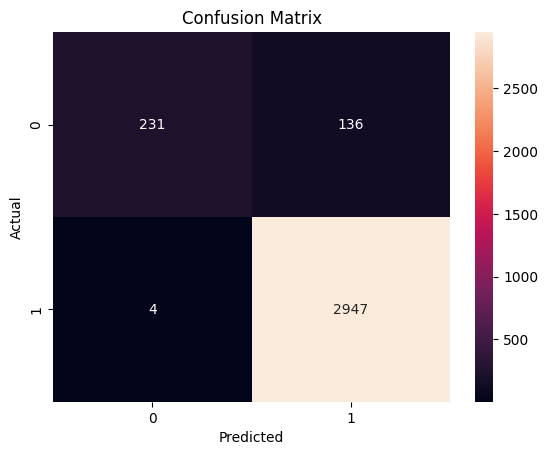

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### STEP 11 — Confidence scores

In [ ]:
probs = model.predict_proba(X_test)
confidence = probs.max(axis=1)

test_df["predicted"] = le.inverse_transform(y_pred)
test_df["confidence"] = confidence

### STEP 12 — Error analysis (MOST IMPORTANT STEP)

In [ ]:
from IPython.display import display

wrong = test_df[test_df["label"] != test_df["predicted"]]

display(wrong[["text", "label", "predicted", "confidence"]].head(20))

,text,label,predicted,confidence
22,PIWeCS: enhancing human/machine agency in an i...,0,1,0.920012
62,Participatory design in Māori cultural context...,0,1,0.600218
65,COP26 local panel: Setting the scene - what's ...,0,1,0.947178
102,Lessons from children in Māori medium for teac...,0,1,0.729188
122,Social deprivation in New Zealand The purpose ...,0,1,0.902509
133,How Maui captured the sun: using a MUD for edu...,0,1,0.969088
178,Paremias xeocosmolóxicas de predición do tempo...,0,1,0.587145
230,A New Technique for Measuring Runup Variation ...,0,1,0.535126
241,Local volunteers respond to the Rena oil spill...,0,1,0.856777
254,Planning the urban foodscape: Policy and regul...,0,1,0.751134


### Analyze Misclassification Types

Misclassification counts:


,label,predicted,count
0,0,1,136
1,1,0,4


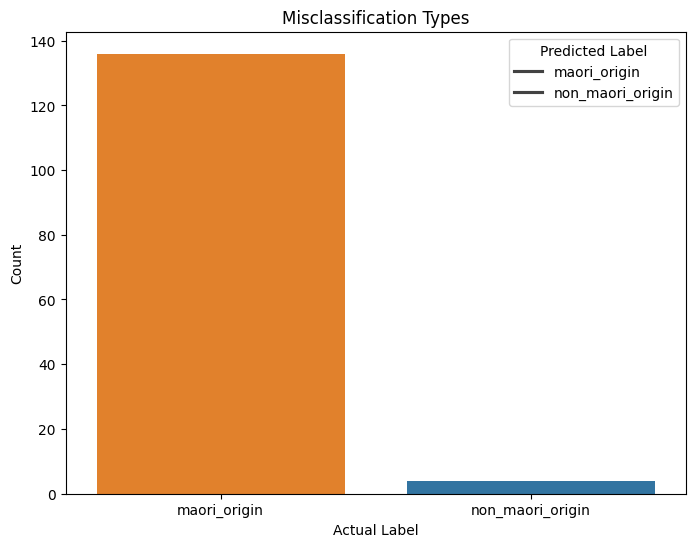

In [ ]:
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns

print('Misclassification counts:')
misclassification_counts = wrong.groupby(['label', 'predicted']).size().reset_index(name='count')
display(misclassification_counts)

# Visualize misclassification types
plt.figure(figsize=(8, 6))
sns.barplot(x='label', y='count', hue='predicted', data=misclassification_counts)
plt.title('Misclassification Types')
plt.xlabel('Actual Label')
plt.ylabel('Count')
plt.xticks(ticks=[0, 1], labels=[id2label[0], id2label[1]])
plt.legend(title='Predicted Label', labels=[id2label[0], id2label[1]])
plt.show()

### Analyze Confidence Scores for Wrong Predictions


Confidence score statistics for wrong predictions:


,confidence
count,140.000000
mean,0.779464
std,0.131560
min,0.507469
25%,0.693774
50%,0.785651
75%,0.893978
max,0.987764


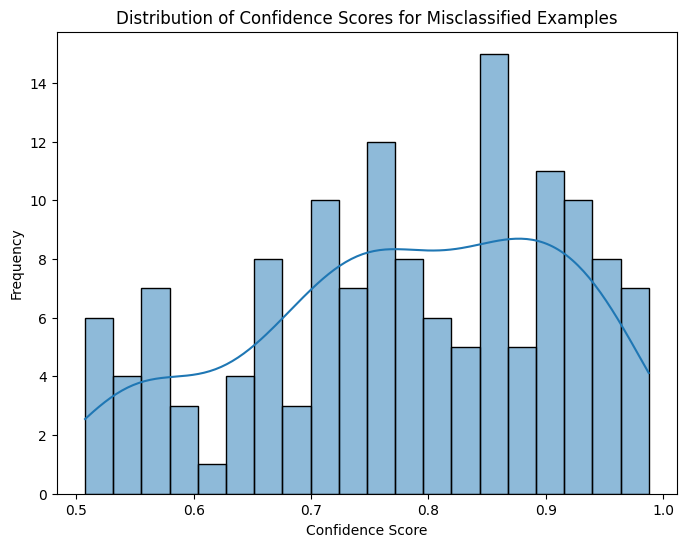

In [ ]:
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns

print('\nConfidence score statistics for wrong predictions:')
display(wrong['confidence'].describe())

plt.figure(figsize=(8, 6))
sns.histplot(wrong['confidence'], bins=20, kde=True)
plt.title('Distribution of Confidence Scores for Misclassified Examples')
plt.xlabel('Confidence Score')
plt.ylabel('Frequency')
plt.show()

In [ ]:
high_confidence_wrong = wrong[wrong['confidence'] > 0.9]

print('\nHigh-confidence misclassified examples:')
display(high_confidence_wrong[['text', 'label', 'predicted', 'confidence']])


High-confidence misclassified examples:


,text,label,predicted,confidence
22,PIWeCS: enhancing human/machine agency in an i...,0,1,0.920012
65,COP26 local panel: Setting the scene - what's ...,0,1,0.947178
122,Social deprivation in New Zealand The purpose ...,0,1,0.902509
133,How Maui captured the sun: using a MUD for edu...,0,1,0.969088
331,Spatial and temporal characteristics of the un...,0,1,0.953669
631,An investigation by LA-ICP-MS of possum tooth ...,0,1,0.955898
693,Boat electrofishing survey of fish abundance i...,0,1,0.905105
733,In vitro cell culture to study microglial infl...,0,1,0.982706
1092,"The source, composition and typology of ‘Limes...",0,1,0.973736
1135,Birds vs. Clams: Assessing the impacts of Sout...,0,1,0.969223


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

# Filter for misclassified 'maori_origin' examples (label 0)
misclassified_maori = wrong[wrong['label'] == 0]

# Extract the text content
maori_texts = misclassified_maori['text']

# Initialize CountVectorizer (can add stop words, ngrams, etc. for more advanced analysis)
# Using stop_words='english' to remove common English words
vectorizer_keywords = CountVectorizer(stop_words='english', max_features=50)

# Fit and transform the text data
X_maori = vectorizer_keywords.fit_transform(maori_texts)

# Get feature names (words)
feature_names = vectorizer_keywords.get_feature_names_out()

# Sum up the counts of each word
word_counts = X_maori.sum(axis=0)

# Create a DataFrame of word counts
word_freq_df = pd.DataFrame({'word': feature_names, 'count': word_counts.tolist()[0]})

# Sort by count in descending order
word_freq_df = word_freq_df.sort_values(by='count', ascending=False)

print('\nTop 20 keywords in misclassified \'maori_origin\' abstracts:')
display(word_freq_df.head(20))


Top 20 keywords in misclassified 'maori_origin' abstracts:


,word,count
25,new,211
49,zealand,175
30,research,137
36,study,125
24,māori,79
37,te,70
8,data,67
7,cultural,65
11,education,63
6,community,60


### STEP 13 — Save your model

In [ ]:
import pickle

pickle.dump(model, open("classifier.pkl", "wb"))
pickle.dump(vectorizer, open("vectorizer.pkl", "wb"))

### STEP 14 — Upload your model to Hugging Face

In [ ]:
from huggingface_hub import HfApi, login
from google.colab import userdata

# Ensure HF_TOKEN is available, though it should be from a previous cell
HF_TOKEN = userdata.get('HF_TOKEN')
login(token=HF_TOKEN, add_to_git_credential=False) # add_to_git_credential=False to avoid interactive prompts

# Define the repository ID for your model
model_repo_id = "dinushiTJ/nz_research_commons_classification_baseline-tfidf"

api = HfApi()

# Create the repository if it doesn't exist
api.create_repo(model_repo_id, repo_type="model", exist_ok=True)

print(f"Uploading model artifacts to Hugging Face Hub under {model_repo_id}...")

# Upload the model and vectorizer files
# These files should have been saved locally by STEP 13
api.upload_file(
    path_or_fileobj="classifier.pkl",
    path_in_repo="classifier.pkl",
    repo_id=model_repo_id,
    repo_type="model",
    token=HF_TOKEN,
    commit_message="Add Logistic Regression classifier"
)
print("classifier.pkl uploaded successfully!")

api.upload_file(
    path_or_fileobj="vectorizer.pkl",
    path_in_repo="vectorizer.pkl",
    repo_id=model_repo_id,
    repo_type="model",
    token=HF_TOKEN,
    commit_message="Add TfidfVectorizer"
)
print("vectorizer.pkl uploaded successfully!")

print("All model artifacts uploaded successfully!")
print(f"You can view them at: https://huggingface.co/{model_repo_id}")

Uploading model artifacts to Hugging Face Hub under dinushiTJ/nz_research_commons_classification_baseline-tfidf...


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  classifier.pkl              : 100%|##########| 40.7kB / 40.7kB            

No files have been modified since last commit. Skipping to prevent empty commit.


...

New Data Upload               : |          |  0.00B /  0.00B            

  vectorizer.pkl              : 100%|##########|  187kB /  187kB            

  vectorizer.pkl              : 100%|##########|  187kB /  187kB            

No files have been modified since last commit. Skipping to prevent empty commit.


vectorizer.pkl uploaded successfully!
All model artifacts uploaded successfully!
You can view them at: https://huggingface.co/dinushiTJ/nz_research_commons_classification_baseline-tfidf
